# Tugas 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
data = pd.read_csv('voice.csv')
data.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [3]:
data.info()
print('Jumlah nilai kosong:', data.isna().sum().sum())
print(data['label'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

In [4]:
X = data.drop(columns='label')
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data latih: 2217
Jumlah data uji: 951


In [5]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('seleksi', SelectKBest(score_func=f_classif)),
    ('knn', KNeighborsClassifier())
])

parameter = {
    'seleksi__k': list(range(1, X_train.shape[1] + 1)),
    'knn__n_neighbors': list(range(1, 31))
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pencarian = GridSearchCV(
    pipeline, parameter, scoring='accuracy', cv=cv,
    n_jobs=2, return_train_score=True
)
pencarian.fit(X_train, y_train)
print('Parameter terbaik:', pencarian.best_params_)
print(f'Akurasi validasi silang terbaik: {pencarian.best_score_:.6f}')

Parameter terbaik: {'knn__n_neighbors': 6, 'seleksi__k': 10}
Akurasi validasi silang terbaik: 0.978799


In [6]:
hasil_cv = pd.DataFrame(pencarian.cv_results_)
hasil_cv['jumlah_fitur'] = hasil_cv['param_seleksi__k'].astype(int)
hasil_cv['k'] = hasil_cv['param_knn__n_neighbors'].astype(int)

hasil_cv[['jumlah_fitur', 'k', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values(
    ['mean_test_score', 'jumlah_fitur', 'k'], ascending=[False, True, True]
).head(10)

,jumlah_fitur,k,mean_train_score,mean_test_score,std_test_score
109,10,6,0.980492,0.978799,0.003061
105,6,6,0.983198,0.978350,0.003368
65,6,4,0.984326,0.978347,0.003076
69,10,4,0.984326,0.977900,0.003863
70,11,4,0.984438,0.977898,0.003604
68,9,4,0.984213,0.977450,0.004018
85,6,5,0.981732,0.977448,0.004030
125,6,7,0.980266,0.977447,0.004731
47,8,3,0.986243,0.977446,0.005152
89,10,5,0.981169,0.977446,0.005146


In [7]:
model_terbaik = pencarian.best_estimator_
jumlah_fitur_terbaik = pencarian.best_params_['seleksi__k']
k_terbaik = pencarian.best_params_['knn__n_neighbors']
fitur_terbaik = X_train.columns[model_terbaik.named_steps['seleksi'].get_support()].tolist()

print('Jumlah fitur terbaik:', jumlah_fitur_terbaik)
print('Fitur yang digunakan:', ', '.join(fitur_terbaik))
print('Nilai k terbaik:', k_terbaik)

peringkat_fitur = pd.DataFrame({
    'Fitur': X_train.columns,
    'Skor ANOVA': model_terbaik.named_steps['seleksi'].scores_,
    'Dipilih': model_terbaik.named_steps['seleksi'].get_support()
})
peringkat_fitur.sort_values('Skor ANOVA', ascending=False)

Jumlah fitur terbaik: 10
Fitur yang digunakan: meanfreq, sd, median, Q25, IQR, sp.ent, sfm, centroid, meanfun, mindom
Nilai k terbaik: 6


,Fitur,Skor ANOVA,Dipilih
12,meanfun,4943.437345,True
5,IQR,1378.911196,True
3,Q25,777.728663,True
8,sp.ent,688.925702,True
1,sd,669.471838,True
9,sfm,336.615777,True
11,centroid,280.468247,True
0,meanfreq,280.468247,True
2,median,183.661726,True
16,mindom,86.605771,True


In [8]:
y_pred_train = model_terbaik.predict(X_train)
y_pred = model_terbaik.predict(X_test)

akurasi_train = accuracy_score(y_train, y_pred_train)
akurasi_test = accuracy_score(y_test, y_pred)

print(f'Akurasi data latih: {akurasi_train:.6f}')
print(f'Akurasi data uji: {akurasi_test:.6f}')
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred, labels=['female', 'male']))
print('Laporan Klasifikasi:')
print(classification_report(y_test, y_pred, labels=['female', 'male']))

Akurasi data latih: 0.978800
Akurasi data uji: 0.984227
Confusion Matrix:
[[468   8]
 [  7 468]]
Laporan Klasifikasi:
              precision    recall  f1-score   support

      female       0.99      0.98      0.98       476
        male       0.98      0.99      0.98       475

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



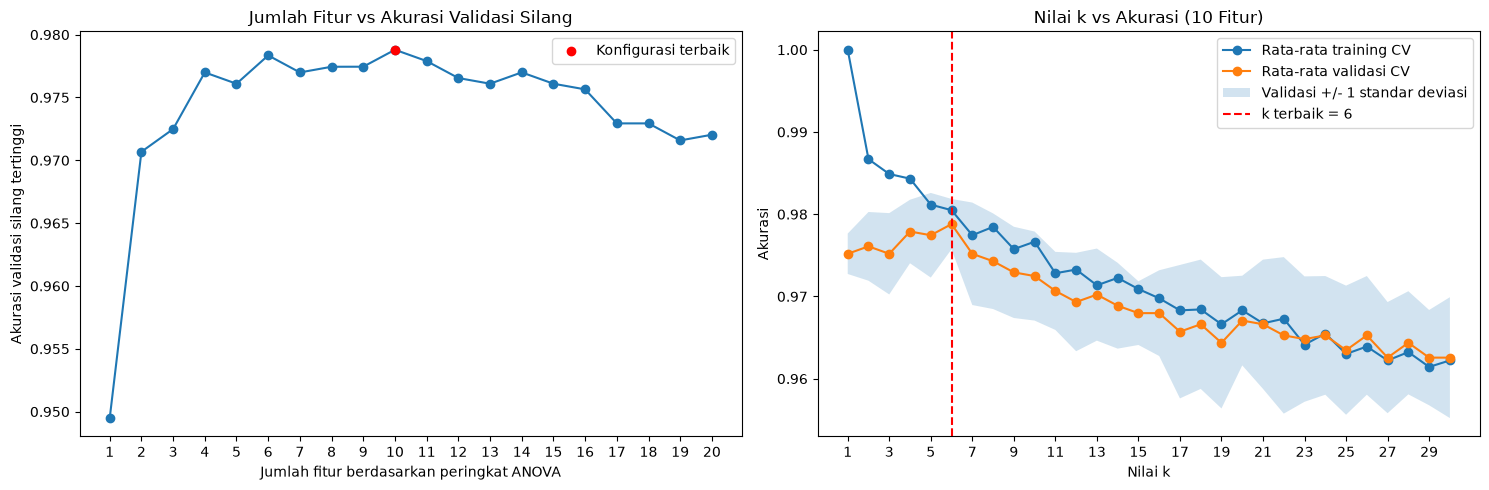

In [9]:
hasil_fitur = hasil_cv.groupby('jumlah_fitur')['mean_test_score'].max()
hasil_k = hasil_cv[hasil_cv['jumlah_fitur'] == jumlah_fitur_terbaik].sort_values('k')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(hasil_fitur.index, hasil_fitur.values, marker='o')
axes[0].scatter(jumlah_fitur_terbaik, pencarian.best_score_, color='red', zorder=3, label='Konfigurasi terbaik')
axes[0].set_xlabel('Jumlah fitur berdasarkan peringkat ANOVA')
axes[0].set_ylabel('Akurasi validasi silang tertinggi')
axes[0].set_title('Jumlah Fitur vs Akurasi Validasi Silang')
axes[0].set_xticks(range(1, X_train.shape[1] + 1))
axes[0].legend()

axes[1].plot(hasil_k['k'], hasil_k['mean_train_score'], marker='o', label='Rata-rata training CV')
axes[1].plot(hasil_k['k'], hasil_k['mean_test_score'], marker='o', label='Rata-rata validasi CV')
axes[1].fill_between(
    hasil_k['k'],
    hasil_k['mean_test_score'] - hasil_k['std_test_score'],
    hasil_k['mean_test_score'] + hasil_k['std_test_score'],
    alpha=0.2, label='Validasi +/- 1 standar deviasi'
)
axes[1].axvline(k_terbaik, color='red', linestyle='--', label=f'k terbaik = {k_terbaik}')
axes[1].set_xlabel('Nilai k')
axes[1].set_ylabel('Akurasi')
axes[1].set_title(f'Nilai k vs Akurasi ({jumlah_fitur_terbaik} Fitur)')
axes[1].set_xticks(range(1, 31, 2))
axes[1].legend()
plt.tight_layout()
plt.show()

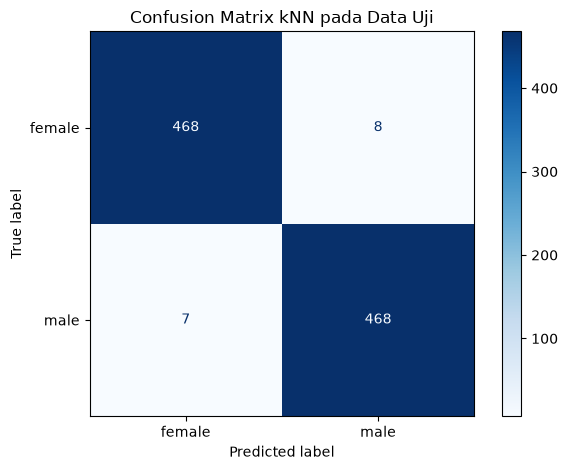

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=['female', 'male'], cmap='Blues', values_format='d'
)
plt.title('Confusion Matrix kNN pada Data Uji')
plt.tight_layout()
plt.show()

2. Percobaan menggunakan 1 sampai 20 fitur teratas berdasarkan skor ANOVA dan nilai k dari 1 sampai 30. Standardisasi serta seleksi fitur dilakukan di dalam pipeline pada setiap fold agar tidak menggunakan informasi data validasi. Konfigurasi terbaik dari 600 kombinasi yang diuji menggunakan 10 fitur, yaitu meanfreq, sd, median, Q25, IQR, sp.ent, sfm, centroid, meanfun, mindom. Rata-rata akurasi validasi silang 5-fold sebesar 97,88%, dibandingkan 97,20% untuk konfigurasi terbaik yang memakai seluruh 20 fitur. Grafik jumlah fitur menunjukkan hasil perbandingan tersebut. Percobaan ini membandingkan kelompok fitur berdasarkan peringkat ANOVA, bukan seluruh kemungkinan kombinasi fitur.

3. Berdasarkan fitur terpilih, nilai k terbaik adalah 6. Nilai ini dipilih karena memperoleh rata-rata akurasi validasi silang tertinggi pada rentang k yang diuji. Pada k=1, akurasi training mencapai 100% tetapi akurasi validasi lebih rendah, yang menunjukkan kecenderungan overfitting. Setelah k=6, akurasi validasi cenderung menurun. Grafik k terhadap akurasi memperlihatkan perbandingan rata-rata akurasi training dan validasi, dengan daerah bayangan menunjukkan satu standar deviasi akurasi validasi. Akurasi training model akhir sebesar 97,88%. Setelah konfigurasi dipilih, akurasi pada data uji yang disisihkan sebesar 98,42%, dengan 936 dari 951 sampel diklasifikasikan dengan benar. Data uji tidak digunakan untuk memilih fitur maupun nilai k.